In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("spotify_streaming_alia.csv", parse_dates=['endTime'])
weather = pd.read_csv("vancouverWeather.csv", parse_dates=['datetime'])

In [3]:
data['datetime'] = data['endTime'].dt.normalize()
weather = weather[['datetime', 'temp', 'cloudcover','icon']]

In [4]:
merged_data = pd.merge(data, weather, on='datetime', how='inner')
merged_data = merged_data[merged_data['genre'].notnull()]
merged_data['icon'] = merged_data['icon'].astype(str).str.lower()
merged_data['genre'] = merged_data['genre'].astype(str).str.lower()
merged_data['weekday'] = merged_data['endTime'].dt.weekday
merged_data['hour'] = merged_data['endTime'].dt.hour

**Balancing Data**

In [6]:
counts = merged_data['genre'].value_counts()
mean = counts.mean() # baseline count for number of samples to choose

In [7]:
merged_data = pd.merge(merged_data, counts, on='genre', how='inner')

In [8]:
song_data = merged_data[merged_data['count'] >= mean.astype(int)] 

In [9]:
genre_list = song_data['genre'].unique()

In [10]:
genre_list

array(['indie', 'anime', 'seen live', 'rnb', 'dream pop', 'soft pop',
       'pop', 'country', 'female vocalists', 'bedroom pop', 'k-pop',
       'jazz', 'instrumental', 'classical', 'classical piano'],
      dtype=object)

In [11]:
samples = []
for genre in genre_list:
    sample_songs = song_data[song_data['genre'] == genre].sample(mean.astype(int))
    samples.append(sample_songs)
sample_data = pd.concat(samples) 

**Machine Learning**

In [13]:
icon_encoder = preprocessing.LabelEncoder()
genre_encoder = preprocessing.LabelEncoder()

sample_data['genre_code'] = genre_encoder.fit_transform(sample_data['genre'])
sample_data['icon_code'] = icon_encoder.fit_transform(sample_data['icon'])

In [14]:
X = sample_data[['temp', 'cloudcover', 'icon_code', 'hour', 'weekday']].values
y = sample_data['genre_code'].values

In [15]:
# Scale Feature for randomforest 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_valid, y_train, y_valid = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [16]:
# train model using balanced data
model = RandomForestClassifier(
    n_estimators=100,        # More trees = better generalization
    max_depth=10,            # Limit tree depth to prevent overfitting
    min_samples_split=2,     # Require more samples to split
    min_samples_leaf=1,      # Require more samples at leaf
    random_state=42,
    class_weight='balanced'  # Handle minor class imbalance better
    )
model.fit(X_train, y_train)
model.score(X_valid, y_valid)

0.2760416666666667

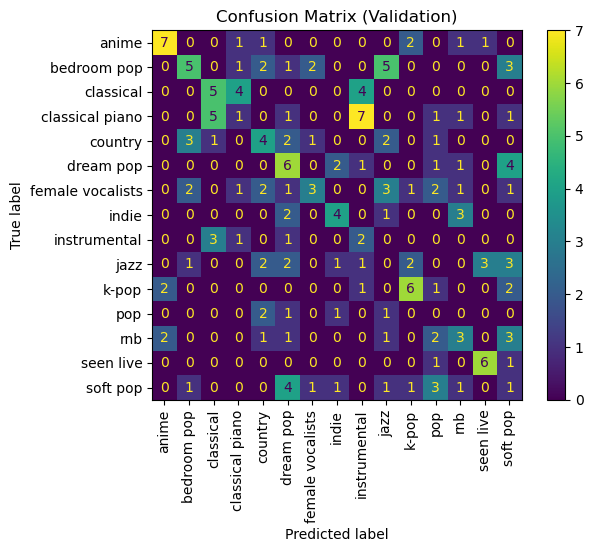

In [17]:
y_pred = model.predict(X_valid)
cm = confusion_matrix(y_valid, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=genre_encoder.classes_)
disp.plot(xticks_rotation=90)
plt.title("Confusion Matrix (Validation)")
plt.show()

In [18]:
probs = model.predict_proba(X_valid)
top5 = np.argsort(probs, axis=1)[:, -5:]

# Reset index so we can loop using i
y_valid = pd.Series(y_valid).reset_index(drop=True)

# Calculate top-5 accuracy
top5_acc = np.mean([y_valid[i] in top5[i] for i in range(len(y_valid))])
print(f"\n Top-5 Genre Accuracy: {top5_acc:.2f}")


 Top-5 Genre Accuracy: 0.65


**Recommendation**

In [20]:
last_day = pd.to_datetime('2025-02-28') # reference date for the last ten day of listening history
# should be the current day, but data is outdated so it uses the last day of the data instead

In [21]:
# use the whole data
last_ten_days = merged_data[merged_data['datetime'] > (last_day - pd.Timedelta(days=10))] # last ten days

*Sample Weather:* <br>
temp: 12 degree <br>
cloudcover: 83% <br>
icon: clear-day <br>

In [23]:
icon_encoded = icon_encoder.transform(['clear-day'])[0]
hour = 15
weekday = 5
sample_temp = np.array([12, 83, icon_encoded, 15, 5])
sample_temp = sample_temp.reshape(1,-1)

In [24]:
genre = genre_encoder.inverse_transform(model.predict(sample_temp))[0]

In [25]:
matched_genre = last_ten_days[last_ten_days['genre'] == genre] 
# need to account for genre that wasn't listened to in the last ten days (aka no matches)

Counts the number of listens to determine which song to predict from the last ten days

In [27]:
track_listens = matched_genre['trackName'].value_counts().reset_index().set_axis(['trackName','track_count'], axis=1)

In [28]:
artist_listens = matched_genre['artistName'].value_counts().reset_index().set_axis(['artistName','artist_count'], axis=1)

In [29]:
prediction_data = pd.merge(last_ten_days, track_listens, on='trackName', how='inner')
prediction_data = pd.merge(prediction_data, artist_listens, on='artistName', how='inner')

In [30]:
song_recs = prediction_data.sort_values(by=['track_count', 'artist_count'], ascending=False) # sort by most listened

In [31]:
songs = song_recs['trackName'].unique()

In [32]:
print("Your top three songs based on the weather temperature are:", songs[0:5])

Your top three songs based on the weather temperature are: ['空に歌えば' 'スターマーカー (Album Mix)' 'Tiny Light' 'unravel' 'Red Swan']
